In [15]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from collections import Counter
import time
import matplotlib.pyplot as plt
import random
import copy
import math

In [3]:
!nvidia-smi

Mon Nov  2 11:00:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.88                 KMD Version: 610.88        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   44C    P0             15W /   60W |       0MiB /   6144MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## Data Preprocessing and Vocabulary Building

In [5]:
class TextProcessor:
    def __init__(self, vocab_size=15000, max_len=64):
        self.vocab_size = vocab_size
        self.max_len = max_len
        self.pad_idx = 0
        self.unk_idx = 1
        self.cls_idx = 2

        # Initialize vocab with special tokens
        self.itos = {0: '[PAD]', 1: '[UNK]', 2: '[CLS]'}
        self.stoi = {'[PAD]': 0, '[UNK]': 1, '[CLS]': 2}

    def build_vocab(self, texts):
        words = []
        for text in texts:
            words.extend(str(text).lower().split())

        # Get most common words, reserving 3 spots for special tokens
        word_counts = Counter(words)
        common_words = word_counts.most_common(self.vocab_size - 3)

        for i, (word, _) in enumerate(common_words):
            self.itos[i + 3] = word
            self.stoi[word] = i + 3

    def encode(self, text):
        # Tokenize and convert to indices
        tokens = str(text).lower().split()
        indices = [self.stoi.get(word, self.unk_idx) for word in tokens]

        # Prepend [CLS] token, pad/truncate to max_len (S=64)
        indices = [self.cls_idx] + indices
        if len(indices) > self.max_len:
            indices = indices[:self.max_len]
        else:
            indices = indices + [self.pad_idx] * (self.max_len - len(indices))

        return indices

# 1. Load Data with header=0 to skip the existing header row
train_df = pd.read_csv('train.csv', header=0, names=['class_index', 'title', 'description'])
test_df = pd.read_csv('test.csv', header=0, names=['class_index', 'title', 'description'])

# Combine title and description
train_df['text'] = train_df['title'] + " " + train_df['description']
test_df['text'] = test_df['title'] + " " + test_df['description']

# Convert 1-indexed classes (1-4) to 0-indexed (0-3)
train_df['class_index'] = train_df['class_index'] - 1
test_df['class_index'] = test_df['class_index'] - 1

# 2. Create balanced subset of 20,000 samples (5,000 per class)
dfs = []
for i in range(4):
    dfs.append(train_df[train_df['class_index'] == i].sample(5000, random_state=42))
train_balanced = pd.concat(dfs).sample(frac=1, random_state=42).reset_index(drop=True)

# 3. Build Processor and Vocab
processor = TextProcessor(vocab_size=15000, max_len=64)
processor.build_vocab(train_balanced['text'].values)

## Dataset and DataLoader

In [6]:
class AGNewsDataset(Dataset):
    def __init__(self, df, processor):
        self.labels = df['class_index'].values
        self.texts = [processor.encode(text) for text in df['text'].values]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return (
            torch.tensor(self.texts[idx], dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.long)
        )

train_dataset = AGNewsDataset(train_balanced, processor)
test_dataset = AGNewsDataset(test_df, processor)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

## Multi-Head Self-Attention (From Scratch)

In [7]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        # Q, K, V projections from scratch
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

    def forward(self, x, mask=None):
        batch_size = x.size(0)

        # 1. Linear projections
        Q = self.W_q(x) # (B, S, d_model)
        K = self.W_k(x)
        V = self.W_v(x)

        # 2. Split heads: (B, S, num_heads, d_k) -> (B, num_heads, S, d_k)
        Q = Q.view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        K = K.view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        V = V.view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)

        # 3. Scaled Dot-Product Attention: QK^T / sqrt(d_k)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)

        if mask is not None:
            # Mask has shape (B, S). Expand to (B, 1, 1, S)
            mask = mask.unsqueeze(1).unsqueeze(2)
            # Apply -inf to padding tokens so they softmax to 0
            scores = scores.masked_fill(mask == 0, -1e9)

        attention_weights = torch.softmax(scores, dim=-1)

        # Multiply by V
        context = torch.matmul(attention_weights, V)

        # 4. Concatenate heads: (B, num_heads, S, d_k) -> (B, S, d_model)
        context = context.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)

        # 5. Final linear projection
        output = self.W_o(context)

        return output, attention_weights

## Transformer Encoder Block

In [8]:
class TransformerEncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, dim_feedforward=256, dropout=0.1):
        super().__init__()
        self.mhsa = MultiHeadSelfAttention(d_model, num_heads)

        self.ffn = nn.Sequential(
            nn.Linear(d_model, dim_feedforward),
            nn.ReLU(),
            nn.Linear(dim_feedforward, d_model)
        )

        self.layer_norm1 = nn.LayerNorm(d_model)
        self.layer_norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        # Pre-LN Architecture
        attn_out, attn_weights = self.mhsa(self.layer_norm1(x), mask)
        x = x + self.dropout(attn_out)

        ffn_out = self.ffn(self.layer_norm2(x))
        x = x + self.dropout(ffn_out)

        return x, attn_weights

## Full Classification Model

In [9]:
class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model=128, num_heads=4, num_layers=4, max_len=64, num_classes=4):
        super().__init__()

        self.token_embedding = nn.Embedding(vocab_size, d_model)
        # Learnable 1D Positional Embeddings
        self.pos_embedding = nn.Embedding(max_len, d_model)

        self.layers = nn.ModuleList([
            TransformerEncoderLayer(d_model, num_heads)
            for _ in range(num_layers)
        ])

        self.classifier = nn.Linear(d_model, num_classes)
        self.max_len = max_len

    def forward(self, x):
        batch_size, seq_len = x.shape

        # Create boolean key-padding mask (1 for valid, 0 for pad)
        mask = (x != processor.pad_idx)

        # Embeddings + Positional Encoding
        positions = torch.arange(0, seq_len).unsqueeze(0).expand(batch_size, seq_len).to(x.device)

        x = self.token_embedding(x) + self.pos_embedding(positions)

        # Pass through transformer layers
        attn_maps = []
        for layer in self.layers:
            x, attn = layer(x, mask)
            attn_maps.append(attn)

        # Route the final state of the [CLS] token (idx 0) through classification head
        cls_token_state = x[:, 0, :]
        logits = self.classifier(cls_token_state)

        return logits, attn_maps

## Training Loop with Custom Convergence Criteria

In [16]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Experimental configurations
experiments = {
    "Head Study": [
        {"L": 2, "h": 2},
        {"L": 2, "h": 4},
        {"L": 2, "h": 8}
    ],
    "Depth Study": [
        {"L": 2, "h": 4},
        {"L": 4, "h": 4},
        {"L": 6, "h": 4},
        {"L": 8, "h": 4}
    ]
}

# Remove duplicate configurations
all_configs = {}
for study, configs in experiments.items():
    for cfg in configs:
        key = f"L{cfg['L']}_H{cfg['h']}"
        all_configs[key] = cfg

results = {}
trained_models = {}

EPOCHS = 10
LEARNING_RATE = 1e-4

criterion = nn.CrossEntropyLoss()

for config_name, cfg in all_configs.items():

    print("\n" + "=" * 60)
    print(f"Training Configuration: {config_name}")
    print("=" * 60)

    set_seed(42)

    model = TransformerClassifier(
        vocab_size=len(processor.stoi),
        d_model=128,
        num_heads=cfg["h"],
        num_layers=cfg["L"],
        max_len=64,
        num_classes=4
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    epoch_losses = []
    start_time = time.time()

    for epoch in range(EPOCHS):

        model.train()
        total_loss = 0

        for inputs, targets in train_loader:

            inputs = inputs.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()

            logits, _ = model(inputs)

            loss = criterion(logits, targets)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        epoch_losses.append(avg_loss)

        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"Training Loss: {avg_loss:.4f}"
        )

    total_runtime = time.time() - start_time

    # Evaluate on official test dataset
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():

        for inputs, targets in test_loader:

            inputs = inputs.to(device)

            logits, _ = model(inputs)

            predictions = torch.argmax(logits, dim=1)

            y_true.extend(targets.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(
        y_true,
        y_pred,
        average='macro'
    )

    # Store everything for subsequent analysis
    results[config_name] = {
        "L": cfg["L"],
        "h": cfg["h"],
        "losses": epoch_losses,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "runtime": total_runtime,
        "y_true": np.array(y_true),
        "y_pred": np.array(y_pred)
    }

    trained_models[config_name] = copy.deepcopy(model)

    print(f"\nTest Accuracy : {accuracy:.4f}")
    print(f"Macro F1      : {macro_f1:.4f}")
    print(f"Runtime       : {total_runtime:.2f} seconds")

print("\nAll experiments completed!")


Training Configuration: L2_H2
Epoch [1/10] Training Loss: 1.3254
Epoch [2/10] Training Loss: 0.9907
Epoch [3/10] Training Loss: 0.7604
Epoch [4/10] Training Loss: 0.6461
Epoch [5/10] Training Loss: 0.5783
Epoch [6/10] Training Loss: 0.5273
Epoch [7/10] Training Loss: 0.4870
Epoch [8/10] Training Loss: 0.4534
Epoch [9/10] Training Loss: 0.4226
Epoch [10/10] Training Loss: 0.3940

Test Accuracy : 0.8029
Macro F1      : 0.8020
Runtime       : 28.35 seconds

Training Configuration: L2_H4
Epoch [1/10] Training Loss: 1.3235
Epoch [2/10] Training Loss: 0.9766
Epoch [3/10] Training Loss: 0.7252
Epoch [4/10] Training Loss: 0.6067
Epoch [5/10] Training Loss: 0.5333
Epoch [6/10] Training Loss: 0.4803
Epoch [7/10] Training Loss: 0.4392
Epoch [8/10] Training Loss: 0.4045
Epoch [9/10] Training Loss: 0.3740
Epoch [10/10] Training Loss: 0.3427

Test Accuracy : 0.7941
Macro F1      : 0.7934
Runtime       : 30.47 seconds

Training Configuration: L2_H8
Epoch [1/10] Training Loss: 1.3261
Epoch [2/10] Tra

## Summary tables: Test Accuracy and Macro F1

In [17]:
# CELL 2: Summary tables

summary_rows = []

for name, r in results.items():

    summary_rows.append({
        "Configuration": name,
        "Layers (L)": r["L"],
        "Attention Heads (h)": r["h"],
        "Test Accuracy": r["accuracy"],
        "Macro F1": r["macro_f1"],
        "Runtime (seconds)": r["runtime"]
    })

summary_df = pd.DataFrame(summary_rows)

# Head study
head_results = summary_df[
    summary_df["Configuration"].isin(
        ["L2_H2", "L2_H4", "L2_H8"]
    )
].copy()

# Depth study
depth_results = summary_df[
    summary_df["Configuration"].isin(
        ["L2_H4", "L4_H4", "L6_H4", "L8_H4"]
    )
].copy()

print("ATTENTION HEAD COMPARISON")
display(
    head_results.sort_values("Attention Heads (h)")
    .reset_index(drop=True)
)

print("\nTRANSFORMER DEPTH COMPARISON")
display(
    depth_results.sort_values("Layers (L)")
    .reset_index(drop=True)
)

# Save results
summary_df.to_csv("task1_summary_metrics.csv", index=False)

ATTENTION HEAD COMPARISON


,Configuration,Layers (L),Attention Heads (h),Test Accuracy,Macro F1,Runtime (seconds)
0,L2_H2,2,2,0.802895,0.801956,28.345368
1,L2_H4,2,4,0.794079,0.793416,30.467561
2,L2_H8,2,8,0.800000,0.799236,37.230461



TRANSFORMER DEPTH COMPARISON


,Configuration,Layers (L),Attention Heads (h),Test Accuracy,Macro F1,Runtime (seconds)
0,L2_H4,2,4,0.794079,0.793416,30.467561
1,L4_H4,4,4,0.805921,0.805392,54.319677
2,L6_H4,6,4,0.798816,0.797866,78.094902
3,L8_H4,8,4,0.805000,0.805520,102.156465


## Training loss plots

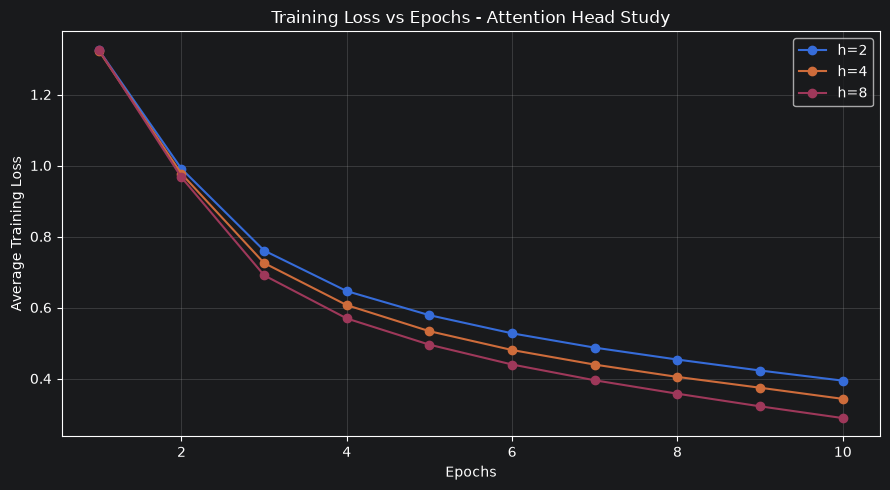

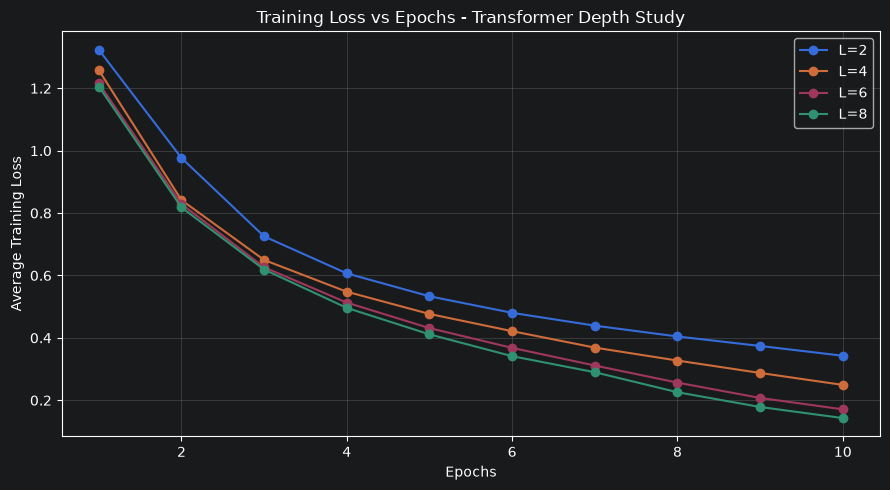

In [18]:
plt.figure(figsize=(9, 5))

for name in ["L2_H2", "L2_H4", "L2_H8"]:

    plt.plot(
        range(1, len(results[name]["losses"]) + 1),
        results[name]["losses"],
        marker='o',
        label=f"h={results[name]['h']}"
    )

plt.title("Training Loss vs Epochs - Attention Head Study")
plt.xlabel("Epochs")
plt.ylabel("Average Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("task1_head_loss.png", dpi=300)
plt.show()


# Transformer depth comparison
plt.figure(figsize=(9, 5))

for name in ["L2_H4", "L4_H4", "L6_H4", "L8_H4"]:

    plt.plot(
        range(1, len(results[name]["losses"]) + 1),
        results[name]["losses"],
        marker='o',
        label=f"L={results[name]['L']}"
    )

plt.title("Training Loss vs Epochs - Transformer Depth Study")
plt.xlabel("Epochs")
plt.ylabel("Average Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("task1_depth_loss.png", dpi=300)
plt.show()

## Best configurations and 4 × 4 confusion matrices

BEST ATTENTION HEAD CONFIGURATION: L2_H2
Accuracy: 0.8028947368421052
Macro F1: 0.8019555066611376

BEST TRANSFORMER DEPTH CONFIGURATION: L8_H4
Accuracy: 0.805
Macro F1: 0.8055197295371633


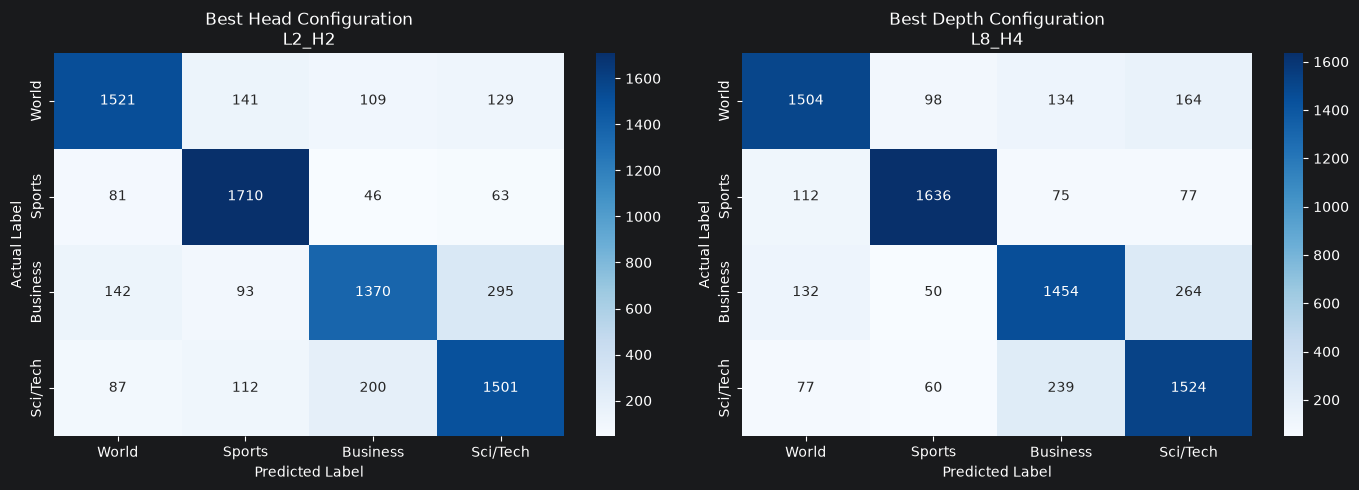

In [19]:
best_head_name = max(
    ["L2_H2", "L2_H4", "L2_H8"],
    key=lambda x: results[x]["macro_f1"]
)

best_depth_name = max(
    ["L2_H4", "L4_H4", "L6_H4", "L8_H4"],
    key=lambda x: results[x]["macro_f1"]
)

print("BEST ATTENTION HEAD CONFIGURATION:", best_head_name)
print("Accuracy:", results[best_head_name]["accuracy"])
print("Macro F1:", results[best_head_name]["macro_f1"])

print("\nBEST TRANSFORMER DEPTH CONFIGURATION:", best_depth_name)
print("Accuracy:", results[best_depth_name]["accuracy"])
print("Macro F1:", results[best_depth_name]["macro_f1"])


# Confusion matrices
class_names = ["World", "Sports", "Business", "Sci/Tech"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, name, title in zip(
    axes,
    [best_head_name, best_depth_name],
    ["Best Head Configuration", "Best Depth Configuration"]
):

    cm = confusion_matrix(
        results[name]["y_true"],
        results[name]["y_pred"],
        labels=[0, 1, 2, 3]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(
        f"{title}\n{name}"
    )

    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.savefig("task1_best_confusion_matrices.png", dpi=300)
plt.show()

## Attention heatmaps across heads

Best Configuration: L8_H4


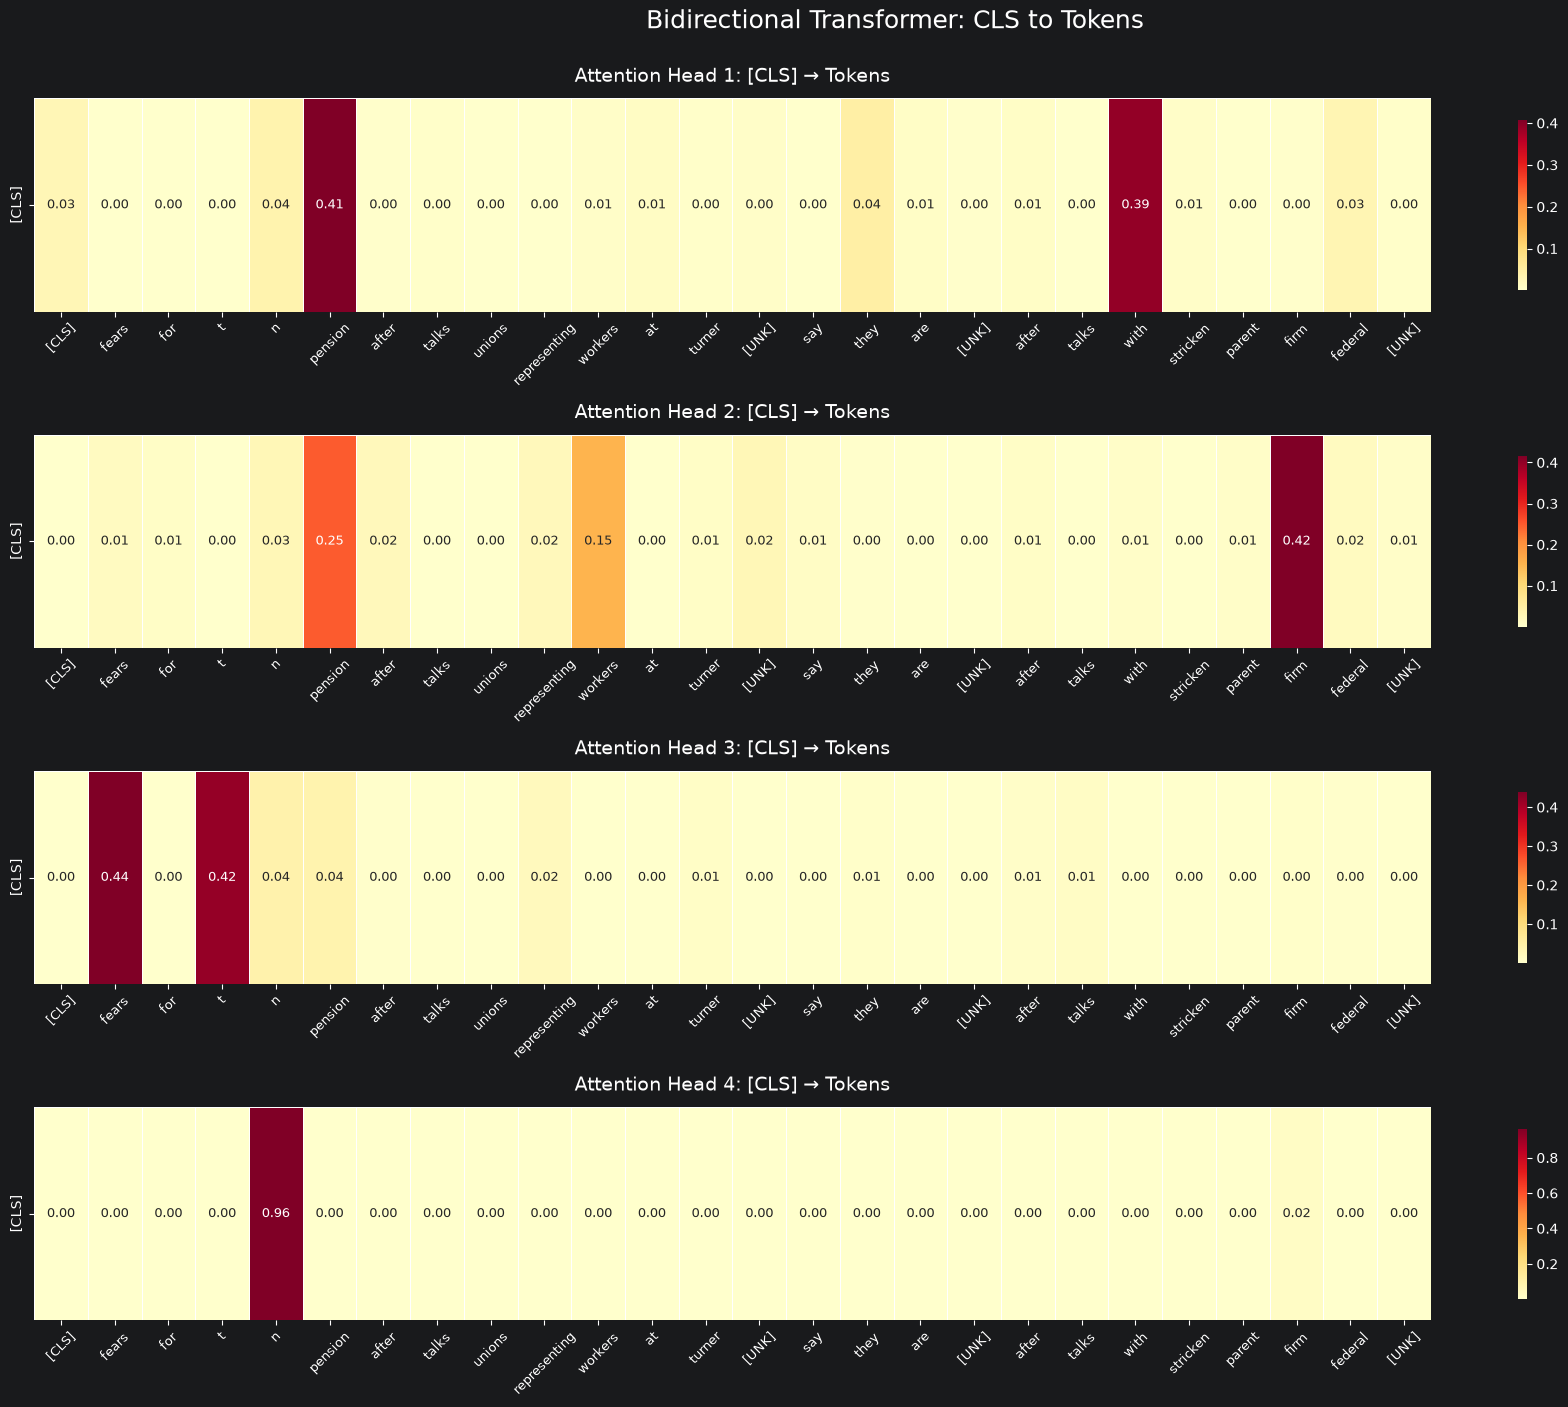

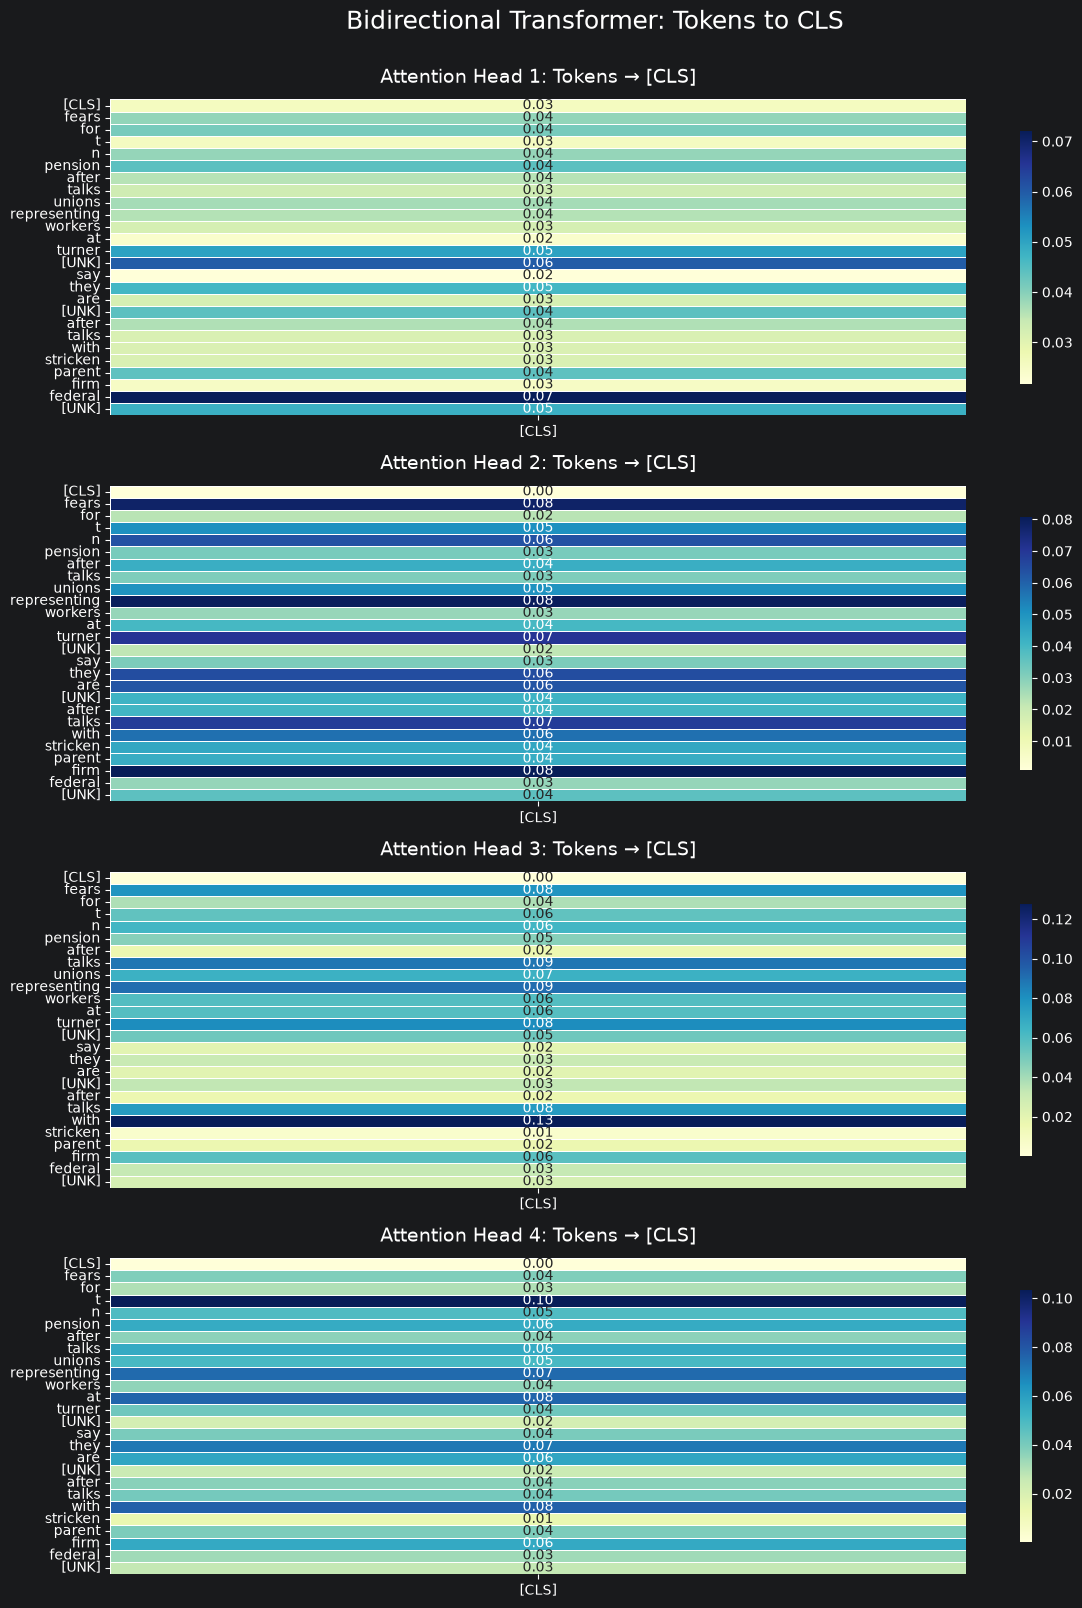

In [22]:
best_config_name = max(
    results.keys(),
    key=lambda x: results[x]["macro_f1"]
)

best_model = trained_models[best_config_name]
best_model.eval()

print("Best Configuration:", best_config_name)

# Select test sample
sample_idx = 0

sample_input = test_dataset[sample_idx][0].unsqueeze(0).to(device)

with torch.no_grad():
    logits, attention_maps = best_model(sample_input)

# Final layer attention
attention = attention_maps[-1][0].detach().cpu().numpy()

# Get tokens
token_ids = sample_input[0].cpu().tolist()

tokens = [
    processor.itos.get(idx, "[UNK]")
    for idx in token_ids
]

# Remove padding
valid_length = sum(
    idx != processor.pad_idx for idx in token_ids
)

tokens = tokens[:valid_length]

attention = attention[:, :valid_length, :valid_length]

num_heads = attention.shape[0]

# -------------------------------------------------
# 1. CLS -> Tokens (All Heads)
# -------------------------------------------------

fig, axes = plt.subplots(
    num_heads, 1,
    figsize=(18, 3.5 * num_heads),
    squeeze=False
)

for h in range(num_heads):

    values = attention[h, 0, :].reshape(1, -1)

    sns.heatmap(
        values,
        ax=axes[h, 0],
        cmap="YlOrRd",
        annot=True,
        fmt=".2f",
        linewidths=0.5,
        xticklabels=tokens,
        yticklabels=["[CLS]"],
        annot_kws={"size": 9},
        cbar_kws={"shrink": 0.8}
    )

    axes[h, 0].set_title(
        f"Attention Head {h+1}: [CLS] → Tokens",
        fontsize=14,
        pad=12
    )

    axes[h, 0].tick_params(
        axis="x",
        labelsize=9,
        rotation=45
    )

plt.suptitle(
    "Bidirectional Transformer: CLS to Tokens",
    fontsize=18,
    y=1.002
)

plt.tight_layout()
plt.savefig(
    "task1_cls_to_tokens.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# -------------------------------------------------
# 2. Tokens -> CLS (All Heads)
# -------------------------------------------------

fig, axes = plt.subplots(
    num_heads, 1,
    figsize=(12, 4 * num_heads),
    squeeze=False
)

for h in range(num_heads):

    values = attention[h, :, 0].reshape(-1, 1)

    sns.heatmap(
        values,
        ax=axes[h, 0],
        cmap="YlGnBu",
        annot=True,
        fmt=".2f",
        linewidths=0.5,
        yticklabels=tokens,
        xticklabels=["[CLS]"],
        annot_kws={"size": 10},
        cbar_kws={"shrink": 0.8}
    )

    axes[h, 0].set_title(
        f"Attention Head {h+1}: Tokens → [CLS]",
        fontsize=14,
        pad=12
    )

    axes[h, 0].tick_params(
        axis="y",
        labelsize=10
    )

plt.suptitle(
    "Bidirectional Transformer: Tokens to CLS",
    fontsize=18,
    y=1.002
)

plt.tight_layout()
plt.savefig(
    "task1_tokens_to_cls.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [25]:
# CELL 6: Empirical Analysis

print("=" * 70)
print("EMPIRICAL ANALYSIS: ATTENTION HEADS AND TRANSFORMER DEPTH")
print("=" * 70)

# -------------------------------------------------
# 1. Effect of Attention Head Count
# -------------------------------------------------

print("\n1. IMPACT OF ATTENTION HEAD COUNT (h)")
print("-" * 60)

head_df = head_results.sort_values("Attention Heads (h)")

for _, row in head_df.iterrows():

    print(
        f"h = {int(row['Attention Heads (h)'])}: "
        f"Accuracy = {row['Test Accuracy']:.4f}, "
        f"Macro F1 = {row['Macro F1']:.4f}, "
        f"Runtime = {row['Runtime (seconds)']:.2f}s"
    )

best_head = head_df.loc[head_df["Macro F1"].idxmax()]
worst_head = head_df.loc[head_df["Macro F1"].idxmin()]


# -------------------------------------------------
# 2. Effect of Transformer Depth
# -------------------------------------------------

print("\n\n2. IMPACT OF TRANSFORMER DEPTH (L)")
print("-" * 60)

depth_df = depth_results.sort_values("Layers (L)")

for _, row in depth_df.iterrows():

    print(
        f"L = {int(row['Layers (L)'])}: "
        f"Accuracy = {row['Test Accuracy']:.4f}, "
        f"Macro F1 = {row['Macro F1']:.4f}, "
        f"Runtime = {row['Runtime (seconds)']:.2f}s"
    )

best_depth = depth_df.loc[depth_df["Macro F1"].idxmax()]

print("\nObservation:")

print(
    f"The best depth configuration is "
    f"L={int(best_depth['Layers (L)'])}, "
    f"with accuracy {best_depth['Test Accuracy']:.4f} "
    f"and Macro F1 {best_depth['Macro F1']:.4f}."
)


# -------------------------------------------------
# 3. Training Stability and Runtime
# -------------------------------------------------

print("\n\n3. TRAINING STABILITY AND COMPUTATIONAL COST")
print("-" * 60)

for name in ["L2_H4", "L4_H4", "L6_H4", "L8_H4"]:

    losses = results[name]["losses"]

    loss_std = np.std(losses)
    loss_reduction = losses[0] - losses[-1]

    print(
        f"{name}: "
        f"Loss reduction = {loss_reduction:.4f}, "
        f"Loss std = {loss_std:.4f}, "
        f"Runtime = {results[name]['runtime']:.2f}s"
    )

# -------------------------------------------------
# 4. Overall Conclusion
# -------------------------------------------------

overall_best = summary_df.loc[summary_df["Macro F1"].idxmax()]

print("\n\n4. OVERALL BEST CONFIGURATION")
print("-" * 60)

print("Configuration:", overall_best["Configuration"])
print("Layers:", int(overall_best["Layers (L)"]))
print("Attention Heads:", int(overall_best["Attention Heads (h)"]))
print("Test Accuracy:", round(overall_best["Test Accuracy"], 4))
print("Macro F1:", round(overall_best["Macro F1"], 4))
print("Runtime:", round(overall_best["Runtime (seconds)"], 2), "seconds")


EMPIRICAL ANALYSIS: ATTENTION HEADS AND TRANSFORMER DEPTH

1. IMPACT OF ATTENTION HEAD COUNT (h)
------------------------------------------------------------
h = 2: Accuracy = 0.8029, Macro F1 = 0.8020, Runtime = 28.35s
h = 4: Accuracy = 0.7941, Macro F1 = 0.7934, Runtime = 30.47s
h = 8: Accuracy = 0.8000, Macro F1 = 0.7992, Runtime = 37.23s


2. IMPACT OF TRANSFORMER DEPTH (L)
------------------------------------------------------------
L = 2: Accuracy = 0.7941, Macro F1 = 0.7934, Runtime = 30.47s
L = 4: Accuracy = 0.8059, Macro F1 = 0.8054, Runtime = 54.32s
L = 6: Accuracy = 0.7988, Macro F1 = 0.7979, Runtime = 78.09s
L = 8: Accuracy = 0.8050, Macro F1 = 0.8055, Runtime = 102.16s

Observation:
The best depth configuration is L=8, with accuracy 0.8050 and Macro F1 0.8055.


3. TRAINING STABILITY AND COMPUTATIONAL COST
------------------------------------------------------------
L2_H4: Loss reduction = 0.9808, Loss std = 0.2961, Runtime = 30.47s
L4_H4: Loss reduction = 1.0087, Loss std